# 04 — Mejora del modelo: Random Forest

**Punto de partida:** en `03_entrenamiento_rf` el Random Forest con las 8 variables del preprocesamiento logró **R² = 0.45** en test (escala log). Fue el mejor modelo, por encima de la regresión lineal (0.28).

**¿Cómo se intentó mejorarlo?** Hay dos caminos:

| Camino | Qué se probó | Resultado en validación |
|---|---|---|
| 1. Ajustar hiperparámetros | `max_features`, `max_depth`, `min_samples_leaf`, más árboles | Casi nada: R² 0.477 → 0.484 |
| 2. Darle más información | Nuevas variables del mismo dataset | **Mucho:** R² 0.48 → 0.64 |

El modelo ya estaba "exprimido" con las 8 variables: el límite no era el algoritmo, sino **la información que recibía**. Por eso este notebook agrega variables nuevas que ya existen en `allpaDB` y vuelve a ajustar el bosque.

## 1. Inicializar

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Configurar estilos
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 5)

## 2. Importar datos

Se cargan los datos preprocesados (las 8 variables del notebook 02) y el dataset original, de donde se sacarán las variables nuevas.

In [2]:
X_train_base = pd.read_csv('../data/processed/X_train.csv')
X_test_base = pd.read_csv('../data/processed/X_test.csv')

y_train_df = pd.read_csv('../data/processed/y_train.csv')
y_test_df = pd.read_csv('../data/processed/y_test.csv')

df_raw = pd.read_csv('../data/raw/allpaDB_layer_HARMONIZED_v1.csv')
df_raw = df_raw[df_raw['ORGC'].notnull()]
df_raw = df_raw[df_raw['ORGC'] <= 100].copy()

print(f"X_train: {X_train_base.shape} | X_test: {X_test_base.shape} | Dataset original filtrado: {df_raw.shape}")

X_train: (17338, 8) | X_test: (4263, 8) | Dataset original filtrado: (21601, 45)


## 3. Variables nuevas

Se eligieron variables que **describen el suelo sin medir directamente el carbono**:

| Variable | Qué es | ¿Por qué ayudaría? |
|---|---|---|
| Horizonte (`layer_name`) | Tipo de capa: A (superficial), B, C (material de origen), O/H (orgánica)… | El horizonte A es donde se acumula la materia orgánica |
| `ECA`, `EMG`, `EK`, `ENA` | Calcio, magnesio, potasio y sodio intercambiables | La materia orgánica retiene estos nutrientes |
| `EAH` | Acidez intercambiable | Suelos ácidos descomponen más lento la materia orgánica |
| `CECPH7` | Capacidad de intercambio catiónico a pH 7 | Gran parte de la CIC del suelo la aporta la materia orgánica |
| Color Munsell (`MSTCOL`) | "Value" (claridad) y "chroma" (intensidad) del color húmedo | Los suelos oscuros tienen más carbono; se mide en campo, es barato |
| `rank` | Posición de la capa dentro del perfil (1 = superficie) | Complementa la profundidad |
| Fuente (`font_type`) | Origen del dato (HD, ZEE, RES) | Cada fuente tiene métodos y zonas distintas |

#### 3.1 Variables descartadas: posible fuga de información (leakage)

- **`BD2` (densidad aparente):** al agregarla, el R² de validación saltaba de 0.61 a 0.84, una mejora demasiado buena. Tiene datos en el 100 % de las capas de algunas fuentes y valores con muchos decimales, lo que indica que **fue estimada con una fórmula (función de pedotransferencia) que usa el propio carbono orgánico** junto con la textura. Usarla sería darle al modelo la respuesta escondida.
- **`NITKJD` (nitrógeno total):** es legítima, pero se mide en el mismo análisis de laboratorio que el carbono. Si ya se tiene el nitrógeno, normalmente ya se tiene el carbono, así que no sirve para el objetivo de **ahorrar laboratorio**.

In [3]:
# Comprobación de leakage: ¿BD2 se puede predecir casi perfecto con textura + carbono?
check = df_raw[df_raw['BD2'].notnull()][['BD2', 'SAND', 'CLAY', 'ORGC']].dropna()

rf_check = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf_check.fit(check[['SAND', 'CLAY', 'ORGC']], check['BD2'])
print(f"R² de BD2 explicada por SAND + CLAY + ORGC (train): {r2_score(check['BD2'], rf_check.predict(check[['SAND', 'CLAY', 'ORGC']])):.3f}")

R² de BD2 explicada por SAND + CLAY + ORGC (train): 0.898


#### 3.2 Construir las variables

In [4]:
# Horizonte: primera letra de layer_name, quitando números y paréntesis del inicio (ej. "2Bt" → "B")
horizonte = df_raw['layer_name'].fillna('').str.replace(r'^[\d\(\)\s]+', '', regex=True).str[:1].str.upper()
df_raw['horizonte'] = horizonte.where(horizonte.isin(['A', 'B', 'C', 'O', 'H', 'E', 'R']), 'X')  # X = otro / sin dato

# Color Munsell húmedo: "10YR 4/3" → value = 4, chroma = 3
munsell = df_raw['MSTCOL'].fillna('').str.extract(r'(\d+(?:\.\d+)?)\s*/\s*(\d+(?:\.\d+)?)').astype(float)
df_raw['m_value'] = munsell[0]
df_raw['m_chroma'] = munsell[1]

# Posición de la capa dentro del perfil
df_raw['rank'] = df_raw.groupby('profile_code')['upper_depth'].rank(method='first')

df_raw['horizonte'].value_counts()

horizonte
A    8656
C    6636
B    3127
X    3022
O      57
H      55
R      35
E      13
Name: count, dtype: int64

#### 3.3 Separar train / test por perfil

Se repite la misma división del notebook 02 (`random_state=42`), para que las filas coincidan con `X_train.csv` y `X_test.csv`.

In [5]:
profiles = df_raw['profile_code'].unique()
train_profiles, test_profiles = train_test_split(profiles, test_size=0.2, random_state=42)

train_raw = df_raw[df_raw['profile_code'].isin(train_profiles)].reset_index(drop=True)
test_raw = df_raw[df_raw['profile_code'].isin(test_profiles)].reset_index(drop=True)

print(f"Train: {len(train_raw)} filas | Test: {len(test_raw)} filas")
print(f"ORGC coincide con y_train: {np.allclose(train_raw['ORGC'].values, y_train_df['ORGC'].values)}")
print(f"ORGC coincide con y_test: {np.allclose(test_raw['ORGC'].values, y_test_df['ORGC'].values)}")

Train: 17338 filas | Test: 4263 filas
ORGC coincide con y_train: True
ORGC coincide con y_test: True


#### 3.4 Imputación de las variables nuevas

Igual que en el preprocesamiento: los faltantes se imputan con la **mediana** (estas variables son asimétricas), y el imputador se ajusta **solo con train**. Las variables categóricas (horizonte y fuente) se convierten en columnas 0/1 (one-hot); no necesitan escalado porque se usa un modelo de árboles.

In [6]:
nuevas_num = ['ECA', 'EMG', 'EK', 'ENA', 'EAH', 'CECPH7', 'm_value', 'm_chroma', 'rank']

missing_new = pd.DataFrame({
    'Columna': nuevas_num,
    'Faltantes train (%)': (train_raw[nuevas_num].isnull().mean() * 100).round(2).values})
missing_new

,Columna,Faltantes train (%)
0,ECA,19.35
1,EMG,19.19
2,EK,19.22
3,ENA,20.37
4,EAH,15.60
5,CECPH7,47.66
6,m_value,51.70
7,m_chroma,51.70
8,rank,4.48


In [7]:
imputer_new = SimpleImputer(strategy='median')
imputer_new.fit(train_raw[nuevas_num])

hz_cols = ['hz_A', 'hz_B', 'hz_C', 'hz_O', 'hz_H', 'hz_E', 'hz_R', 'hz_X']
src_cols = ['src_HD', 'src_RES', 'src_ZEE']

def agregar_variables(df, X_base):
    num = pd.DataFrame(imputer_new.transform(df[nuevas_num]), columns=nuevas_num)
    hz = pd.get_dummies(df['horizonte'], prefix='hz').astype(int).reindex(columns=hz_cols, fill_value=0)
    src = pd.get_dummies(df['font_type'], prefix='src').astype(int).reindex(columns=src_cols, fill_value=0)
    return pd.concat([X_base, hz, src, num], axis=1)

X_train_full = agregar_variables(train_raw, X_train_base)
X_test = agregar_variables(test_raw, X_test_base)

print(f"X_train: {X_train_full.shape} | X_test: {X_test.shape} | NaN: {X_train_full.isnull().sum().sum() + X_test.isnull().sum().sum()}")
X_train_full.head()

X_train: (17338, 28) | X_test: (4263, 28) | NaN: 0


,depth_mid,thickness,PHAQ,SILT,CLAY,TCEQ,ELCOSP,ECEC,hz_A,hz_B,hz_C,hz_O,hz_H,hz_E,hz_R,hz_X,src_HD,src_RES,src_ZEE,ECA,EMG,EK,ENA,EAH,CECPH7,m_value,m_chroma,rank
0,5.0,2.397895,8.2,8.0,2.0,0.615186,0.709328,1.175573,0,0,1,0,0,0,0,0,1,0,0,1.84,0.16,0.20,0.04,0.0,2.24,4.0,3.0,1.0
1,25.0,3.433987,8.5,4.0,0.0,0.717840,0.570137,0.858662,0,0,1,0,0,0,0,0,1,0,0,1.07,0.13,0.11,0.05,0.0,1.36,4.0,3.0,2.0
2,47.5,2.772589,8.5,6.0,0.0,0.506818,0.854942,1.098612,0,0,1,0,0,0,0,0,1,0,0,1.61,0.14,0.19,0.06,0.0,2.00,4.0,3.0,3.0
3,72.5,3.583519,8.4,4.0,0.0,0.565314,0.972392,1.043804,0,0,1,0,0,0,0,0,1,0,0,1.51,0.15,0.14,0.04,0.0,1.84,4.0,3.0,4.0
4,145.0,4.709530,8.0,54.0,6.0,0.173953,1.407876,2.170196,0,0,1,0,0,0,0,0,1,0,0,7.25,0.23,0.22,0.06,0.0,7.76,4.0,3.0,5.0


## 4. Conjunto de validación

Igual que en el notebook 03: 20 % de los perfiles de train se separan para validación.

In [8]:
tr_profiles, val_profiles = train_test_split(train_profiles, test_size=0.2, random_state=42)

mask_tr = np.isin(train_raw['profile_code'], tr_profiles)
mask_val = np.isin(train_raw['profile_code'], val_profiles)

X_train = X_train_full[mask_tr]
X_val = X_train_full[mask_val]

y_train = y_train_df['ORGC_log'][mask_tr]
y_val = y_train_df['ORGC_log'][mask_val]
y_test = y_test_df['ORGC_log']

sizes = [len(X_train), len(X_val), len(X_test)]
total = sum(sizes)
split_summary = pd.DataFrame({
    'Conjunto': ['Train', 'Validación', 'Test'],
    'Conteo': sizes,
    'Porcentaje': [f"{s/total*100:.1f}%" for s in sizes]})
split_summary

,Conjunto,Conteo,Porcentaje
0,Train,13897,64.3%
1,Validación,3441,15.9%
2,Test,4263,19.7%


In [9]:
def report_metrics(y_true, y_pred, algorithm="", verbose=False):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    label = f"{algorithm}"
    if verbose==True:
        print(f"{label}: MAE={mae:.4f}, RMSE={rmse:.4f}, R²={r2:.4f}")
    return {'algorithm': algorithm,'mae': mae, 'rmse': rmse, 'r2': r2}

## 5. Modelo anterior (referencia)

Se vuelve a entrenar el Random Forest del notebook 03 (8 variables, `max_depth=15`, `min_samples_leaf=1`) para compararlo en las mismas condiciones.

In [10]:
cols_base = list(X_train_base.columns)

rf_anterior = RandomForestRegressor(n_estimators=200, max_depth=15, min_samples_leaf=1, random_state=42, n_jobs=-1)
rf_anterior.fit(X_train[cols_base], y_train)

y_val_pred_ant = rf_anterior.predict(X_val[cols_base])
y_test_pred_ant = rf_anterior.predict(X_test[cols_base])

ant_val = report_metrics(y_val, y_val_pred_ant, "RF_anterior_Val", verbose=True)
ant_test = report_metrics(y_test, y_test_pred_ant, "RF_anterior_Test", verbose=True)

RF_anterior_Val: MAE=0.3191, RMSE=0.4820, R²=0.4766
RF_anterior_Test: MAE=0.3207, RMSE=0.4956, R²=0.4504


## 6. Búsqueda de hiperparámetros

Ahora se agrega **`max_features`**: la fracción de variables que cada árbol puede considerar en cada división. Con más variables, usar solo una parte hace que los árboles sean más distintos entre sí y el promedio del bosque mejore.

In [11]:
max_features_list = [0.33, 0.5, 0.7, 1.0]
max_depths = [15, 25]
min_samples_leafs = [1, 3]

results_rf = []

for mf in max_features_list:
    for md in max_depths:
        for msl in min_samples_leafs:
            rf = RandomForestRegressor(
                n_estimators=200,
                max_features=mf,                 # fracción de variables por división
                max_depth=md,                    # profundidad máxima
                min_samples_leaf=msl,            # mínimo de muestras por hoja
                random_state=42,
                n_jobs=-1)

            # Entrenar en train
            rf.fit(X_train, y_train)

            # Evaluar en validación
            y_val_pred = rf.predict(X_val)
            rmse = np.sqrt(mean_squared_error(y_val, y_val_pred))
            r2 = r2_score(y_val, y_val_pred)

            results_rf.append({'max_features': mf, 'max_depth': md, 'min_samples_leaf': msl, 'rmse_val': rmse, 'r2_val': r2})

# Compilar resultados y ordenar por RMSE (menor es mejor)
results_rf_df = pd.DataFrame(results_rf).sort_values('rmse_val')
results_rf_df.head()

,max_features,max_depth,min_samples_leaf,rmse_val,r2_val
6,0.50,25,1,0.397698,0.643715
10,0.70,25,1,0.397939,0.643283
2,0.33,25,1,0.398318,0.642602
11,0.70,25,3,0.399960,0.639650
4,0.50,15,1,0.400286,0.639061


In [12]:
# Seleccionar mejor combinacion
best_rf_params = results_rf_df.iloc[0]
best_mf = float(best_rf_params['max_features'])
best_md = int(best_rf_params['max_depth'])
best_msl = int(best_rf_params['min_samples_leaf'])

print(f"Mejores hiperparametros (validacion):")
print(f"  max_features: {best_mf}")
print(f"  max_depth: {best_md}")
print(f"  min_samples_leaf: {best_msl}")
print(f"  R² validacion: {best_rf_params['r2_val']:.4f}")

Mejores hiperparametros (validacion):
  max_features: 0.5
  max_depth: 25
  min_samples_leaf: 1
  R² validacion: 0.6437


## 7. Modelo final

Con los hiperparámetros elegidos, el modelo final se entrena con **train + validación** (todos los perfiles de entrenamiento) y **500 árboles**. Validación ya cumplió su función (elegir hiperparámetros), así que se aprovechan esos datos para aprender más. Test sigue sin tocarse.

In [13]:
rf_best = RandomForestRegressor(n_estimators=500, max_features=best_mf, max_depth=best_md,
                                min_samples_leaf=best_msl, random_state=42, n_jobs=-1)
rf_best.fit(X_train_full, y_train_df['ORGC_log'])

y_test_pred_rf = rf_best.predict(X_test)

rf_test = report_metrics(y_test, y_test_pred_rf, "RF_mejorado_Test")

pd.DataFrame([ant_test, rf_test]).style.format('{:.4f}', subset=['mae', 'rmse', 'r2'])

,algorithm,mae,rmse,r2
0,RF_anterior_Test,0.3207,0.4956,0.4504
1,RF_mejorado_Test,0.2518,0.3952,0.6507


#### 7.1 Métricas en % de carbono orgánico

In [14]:
y_test_pct = y_test_df['ORGC']
y_test_pred_pct = np.expm1(y_test_pred_rf)
y_test_pred_ant_pct = np.expm1(y_test_pred_ant)

ant_test_pct = report_metrics(y_test_pct, y_test_pred_ant_pct, "RF_anterior_test_%")
rf_test_pct = report_metrics(y_test_pct, y_test_pred_pct, "RF_mejorado_test_%")

pd.DataFrame([ant_test_pct, rf_test_pct]).style.format('{:.4f}', subset=['mae', 'rmse', 'r2'])

,algorithm,mae,rmse,r2
0,RF_anterior_test_%,1.3756,4.8696,0.2145
1,RF_mejorado_test_%,1.0910,4.1727,0.4233


#### 7.2 ¿Cuántas veces acierta?

En regresión no hay "acierto exacto". Se cuenta como acierto que el error sea menor a una tolerancia, en puntos de % de carbono.

In [15]:
error_ant = np.abs(y_test_pct - y_test_pred_ant_pct)
error_rf = np.abs(y_test_pct - y_test_pred_pct)

aciertos = pd.DataFrame({
    'Tolerancia': ['± 0.25 %', '± 0.5 %', '± 1 %'],
    'RF anterior (%)': [round((error_ant <= t).mean() * 100, 1) for t in [0.25, 0.5, 1]],
    'RF mejorado (%)': [round((error_rf <= t).mean() * 100, 1) for t in [0.25, 0.5, 1]]})
aciertos

,Tolerancia,RF anterior (%),RF mejorado (%)
0,± 0.25 %,38.4,45.5
1,± 0.5 %,59.7,68.0
2,± 1 %,78.2,83.7


## 8. Análisis de resultados

#### 8.1 Predicción vs. valor real (test)

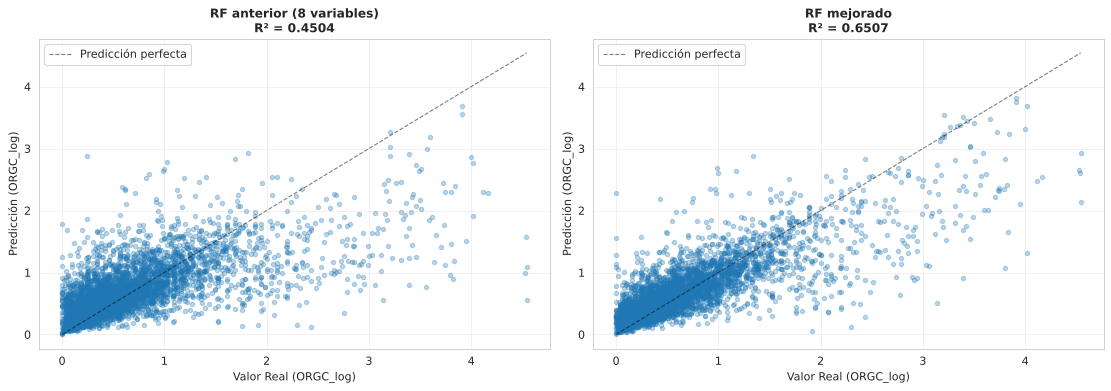

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

models = [('RF anterior (8 variables)', y_test_pred_ant), ('RF mejorado', y_test_pred_rf)]

for idx, (name, y_pred) in enumerate(models):
    ax = axes[idx]
    ax.scatter(y_test, y_pred, alpha=0.3, s=15)

    # Línea y=x (predicción perfecta)
    lims = [y_test.min(), y_test.max()]
    ax.plot(lims, lims, 'k--', lw=1, alpha=0.5, label='Predicción perfecta')

    ax.set_xlabel('Valor Real (ORGC_log)', fontsize=10)
    ax.set_ylabel('Predicción (ORGC_log)', fontsize=10)
    ax.set_title(f'{name}\nR² = {r2_score(y_test, y_pred):.4f}', fontsize=11, fontweight='bold')
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

#### 8.2 Error por rango de carbono

In [17]:
rangos = pd.cut(y_test_pct, bins=[0, 1, 3, 10, 100], labels=['<1 %', '1-3 %', '3-10 %', '>10 %'], include_lowest=True)

error_rango_df = pd.DataFrame({
    'Capas': pd.Series(rangos).value_counts().sort_index().values,
    'MAE anterior (%)': error_ant.groupby(rangos, observed=False).mean().round(3).values,
    'MAE mejorado (%)': error_rf.groupby(rangos, observed=False).mean().round(3).values},
    index=['<1 %', '1-3 %', '3-10 %', '>10 %'])
error_rango_df

,Capas,MAE anterior (%),MAE mejorado (%)
<1 %,2697,0.436,0.313
1-3 %,1062,0.800,0.668
3-10 %,367,2.894,2.401
>10 %,137,20.270,16.167


#### 8.3 Importancia de variables

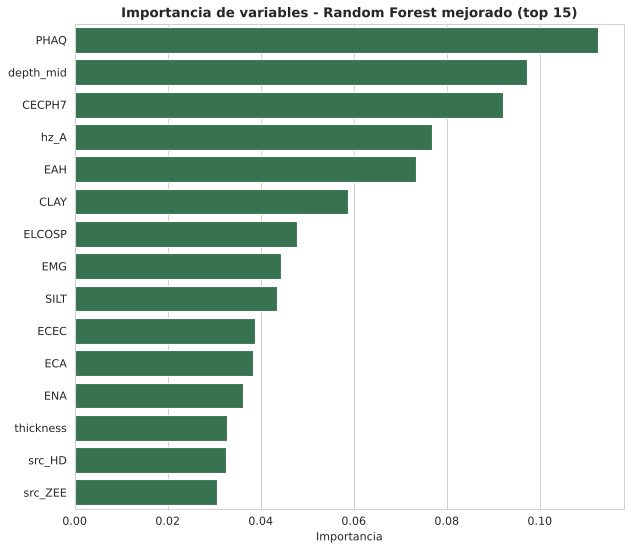

In [18]:
importancias = pd.DataFrame({
    'feature': X_train_full.columns,
    'importancia': rf_best.feature_importances_}).sort_values('importancia', ascending=False)

fig, ax = plt.subplots(figsize=(8, 7))
sns.barplot(data=importancias.head(15), x='importancia', y='feature', color='#2E7D4F', ax=ax)
ax.set_title('Importancia de variables - Random Forest mejorado (top 15)', fontsize=12, fontweight='bold')
ax.set_xlabel('Importancia')
ax.set_ylabel('')
plt.tight_layout()
plt.show()

## 9. Guardar resultados

In [19]:
metricas = pd.DataFrame([ant_val, ant_test, rf_test, ant_test_pct, rf_test_pct])
metricas.to_csv('../data/processed/metricas_random_forest_mejorado.csv', index=False)

pd.DataFrame({'ORGC_real': y_test_pct.values, 'ORGC_pred': y_test_pred_pct}).to_csv('../data/processed/predicciones_test_rf_mejorado.csv', index=False)

print("Archivos guardados en ../data/processed/")

Archivos guardados en ../data/processed/


## 10. Conclusiones

| Métrica (test) | RF anterior | RF mejorado |
|---|---|---|
| R² (escala log) | 0.45 | **0.65** |
| R² (en %) | 0.21 | **0.42** |
| MAE (en %) | 1.38 | **1.09** |
| Aciertos con error ≤ ±1 % | 78 % | **84 %** |

1. **Lo que más mejoró el modelo fue la información, no los hiperparámetros.** Con las 8 variables, ajustar el bosque solo subía el R² en ~0.01. Al agregar horizonte, cationes intercambiables, CIC a pH 7 y color del suelo, el R² de test pasó de 0.45 a **0.65**.
2. **Mejoró en todos los rangos de carbono**, incluso en los suelos orgánicos (> 10 %), aunque ahí el error sigue siendo alto (~16 puntos) porque hay muy pocas capas de ese tipo.
3. **Se evitó leakage:** `BD2` se descartó porque se calculó a partir del carbono (textura + ORGC la explican con R² = 0.90), y `NITKJD` porque se mide junto con el carbono en laboratorio.
4. **Hiperparámetros finales:** 500 árboles, `max_features=0.5`, `max_depth=25`, `min_samples_leaf=1`, entrenado con train + validación.